In [4]:
import pandas as pd 
hotels = pd.read_csv("/kaggle/input/hoteltheme/hotels.csv") 
reviews = pd.read_csv("/kaggle/input/hoteltheme/reviews.csv") 
users = pd.read_csv("/kaggle/input/hoteltheme/users.csv")

In [5]:
print("hotels info")
print(hotels.info())
print("reviews info")
print(reviews.info())
print("users info")
print(users.info())

hotels info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   hotel_id              25 non-null     int64  
 1   hotel_name            25 non-null     object 
 2   city                  25 non-null     object 
 3   country               25 non-null     object 
 4   star_rating           25 non-null     int64  
 5   lat                   25 non-null     float64
 6   lon                   25 non-null     float64
 7   cleanliness_base      25 non-null     float64
 8   comfort_base          25 non-null     float64
 9   facilities_base       25 non-null     float64
 10  location_base         25 non-null     float64
 11  staff_base            25 non-null     float64
 12  value_for_money_base  25 non-null     float64
dtypes: float64(8), int64(2), object(3)
memory usage: 2.7+ KB
None
reviews info
<class 'pandas.core.frame.DataFrame'>
Ra

In [6]:
hotels_rename = {
    'hotel_id': 'hotel_id',          
    'hotel_name': 'hotel_name',
    'city': 'hotel_city',
    'country': 'hotel_country',     
    'star_rating': 'hotel_star_rating',
    'lat': 'hotel_lat',
    'lon': 'hotel_lon',
    'cleanliness_base': 'hotel_cleanliness_base',
    'comfort_base': 'hotel_comfort_base',
    'facilities_base': 'hotel_facilities_base',
    'location_base': 'hotel_location_base',
    'staff_base': 'hotel_staff_base',
    'value_for_money_base': 'hotel_value_for_money_base'
}

reviews_rename = {
    'review_id': 'review_id',
    'user_id': 'user_id',            
    'hotel_id': 'hotel_id',            
    'review_date': 'review_date',
    'score_overall': 'score_overall',
    'score_cleanliness': 'score_cleanliness',
    'score_comfort': 'score_comfort',
    'score_facilities': 'score_facilities',
    'score_location': 'score_location',
    'score_staff': 'score_staff',
    'score_value_for_money': 'score_value_for_money',
    'review_text': 'review_text'
}

users_rename = {
    'user_id': 'user_id',          
    'user_gender': 'user_gender',
    'country': 'user_country',       
    'age_group': 'user_age_group',
    'traveller_type': 'user_traveller_type',
    'join_date': 'user_join_date'
}

#Apply renames
hotels = hotels.rename(columns=hotels_rename)
reviews = reviews.rename(columns=reviews_rename)
users = users.rename(columns=users_rename)

# quick view of columns after rename
print("hotels cols:", hotels.columns.tolist())
print("reviews cols:", reviews.columns.tolist())
print("users cols:", users.columns.tolist())

hotels cols: ['hotel_id', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_lat', 'hotel_lon', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']
reviews cols: ['review_id', 'user_id', 'hotel_id', 'review_date', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'review_text']
users cols: ['user_id', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'user_join_date']


In [7]:
# Merge reviews with users on user_id
reviews_users = pd.merge(
    reviews,
    users,
    on='user_id',
    how='left',  # keep all reviews even if user info missing
    validate='many_to_one'  # many reviews to one user
)


# Merge the result with hotels on hotel_id
merged_df = pd.merge(
    reviews_users,
    hotels,
    on='hotel_id',
    how='left',  # keep all reviews even if hotel info missing
    validate='many_to_one'  # many reviews to one hotel
)

In [8]:
columns_to_drop = [
    'review_text',
    'review_date',
    'user_join_date',
    'hotel_lat',
    'hotel_lon'
]

# Drop the columns
merged_df = merged_df.drop(columns=columns_to_drop)
print(f"Dropped: {columns_to_drop}")
print(f"Dataset shape after dropping columns: {merged_df.shape}")
print(f"Final columns list:\n{merged_df.columns.tolist()}")

Dropped: ['review_text', 'review_date', 'user_join_date', 'hotel_lat', 'hotel_lon']
Dataset shape after dropping columns: (50000, 24)
Final columns list:
['review_id', 'user_id', 'hotel_id', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']


In [9]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   review_id                   50000 non-null  int64  
 1   user_id                     50000 non-null  int64  
 2   hotel_id                    50000 non-null  int64  
 3   score_overall               50000 non-null  float64
 4   score_cleanliness           50000 non-null  float64
 5   score_comfort               50000 non-null  float64
 6   score_facilities            50000 non-null  float64
 7   score_location              50000 non-null  float64
 8   score_staff                 50000 non-null  float64
 9   score_value_for_money       50000 non-null  float64
 10  user_gender                 50000 non-null  object 
 11  user_country                50000 non-null  object 
 12  user_age_group              50000 non-null  object 
 13  user_traveller_type         500

# Question 1: Which city is best for each traveler type?

In [11]:
print("different travel types:" , merged_df['user_traveller_type'].unique())
print("-------------------------")
print("different cities:" ,merged_df['hotel_city'].unique())

different travel types: ['Solo' 'Couple' 'Business' 'Family']
-------------------------
different cities: ['New York' 'Tokyo' 'Cairo' 'Barcelona' 'Moscow' 'Sydney' 'Buenos Aires'
 'Singapore' 'Mumbai' 'Cape Town' 'Berlin' 'Wellington' 'Paris' 'Shanghai'
 'Lagos' 'London' 'Bangkok' 'Istanbul' 'Mexico City' 'Toronto' 'Dubai'
 'Seoul' 'Amsterdam' 'Rome' 'Rio de Janeiro']


In [13]:
#group reviews by traveler type and city
#calculate the average score overall score for each group
#remove the grouping index back to normal index
city_scores = merged_df.groupby(['user_traveller_type', 'hotel_city'])['score_overall'].mean().reset_index()
city_scores.head()

,user_traveller_type,hotel_city,score_overall
0,Business,Amsterdam,8.964348
1,Business,Bangkok,8.886265
2,Business,Barcelona,8.904545
3,Business,Berlin,8.868122
4,Business,Buenos Aires,8.690000


In [15]:
#find the row with the highest score for each traveler type.
best_city_per_type = city_scores.loc[city_scores.groupby('user_traveller_type')['score_overall'].idxmax()]

In [16]:
best_city_per_type 

,user_traveller_type,hotel_city,score_overall
7,Business,Dubai,8.965668
25,Couple,Amsterdam,9.096989
57,Family,Dubai,9.214381
75,Solo,Amsterdam,9.108454


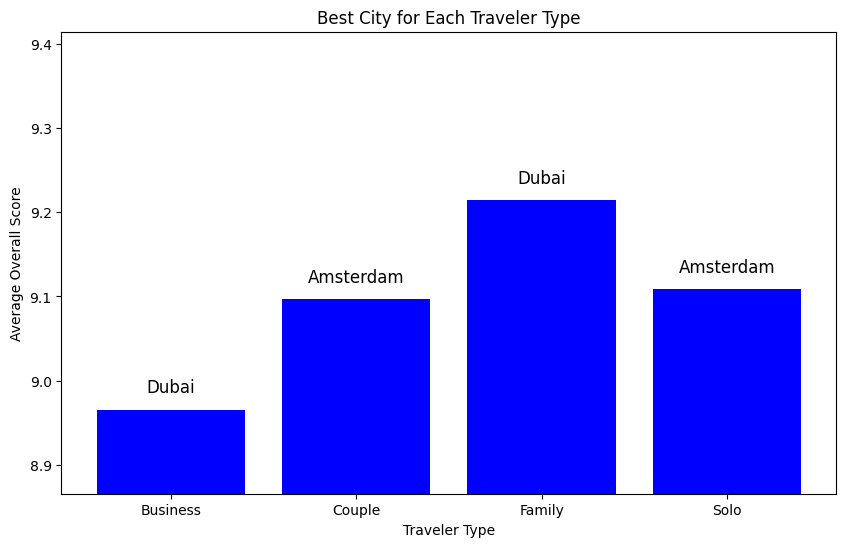

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(best_city_per_type['user_traveller_type'], 
        best_city_per_type['score_overall'], 
        color='blue')


for i, (traveler, city, score) in enumerate(zip(best_city_per_type['user_traveller_type'], 
                                                best_city_per_type['hotel_city'], 
                                                best_city_per_type['score_overall'])):
    plt.text(i, score + 0.02, city, ha='center', fontsize=12)

plt.xlabel("Traveler Type")
plt.ylabel("Average Overall Score")
plt.title("Best City for Each Traveler Type")
plt.ylim(best_city_per_type['score_overall'].min() - 0.1, 
         best_city_per_type['score_overall'].max() + 0.2)
plt.show()

# [](http://)Question 2: Top 3 Countries with Best Value-for-Money per Age Group

In [19]:
print(merged_df['user_age_group'].unique())

['25-34' '35-44' '55+' '45-54' '18-24']


In [20]:
#group age group with country
#get the average score value for money
#reset index
avg_value = merged_df.groupby(['user_age_group', 'hotel_country'])['score_value_for_money'].mean().reset_index()

In [21]:
#sort age group ascending but score value for money in descending
#get top 3
avg_value = avg_value.sort_values(['user_age_group', 'score_value_for_money'], ascending=[True, False])
top3 = avg_value.groupby('user_age_group').head(3) 
top3

,user_age_group,hotel_country,score_value_for_money
4,18-24,China,8.706926
12,18-24,Netherlands,8.704911
3,18-24,Canada,8.661261
29,25-34,China,8.727941
37,25-34,Netherlands,8.683442
44,25-34,Spain,8.625074
54,35-44,China,8.700799
62,35-44,Netherlands,8.693268
63,35-44,New Zealand,8.646429
79,45-54,China,8.722112


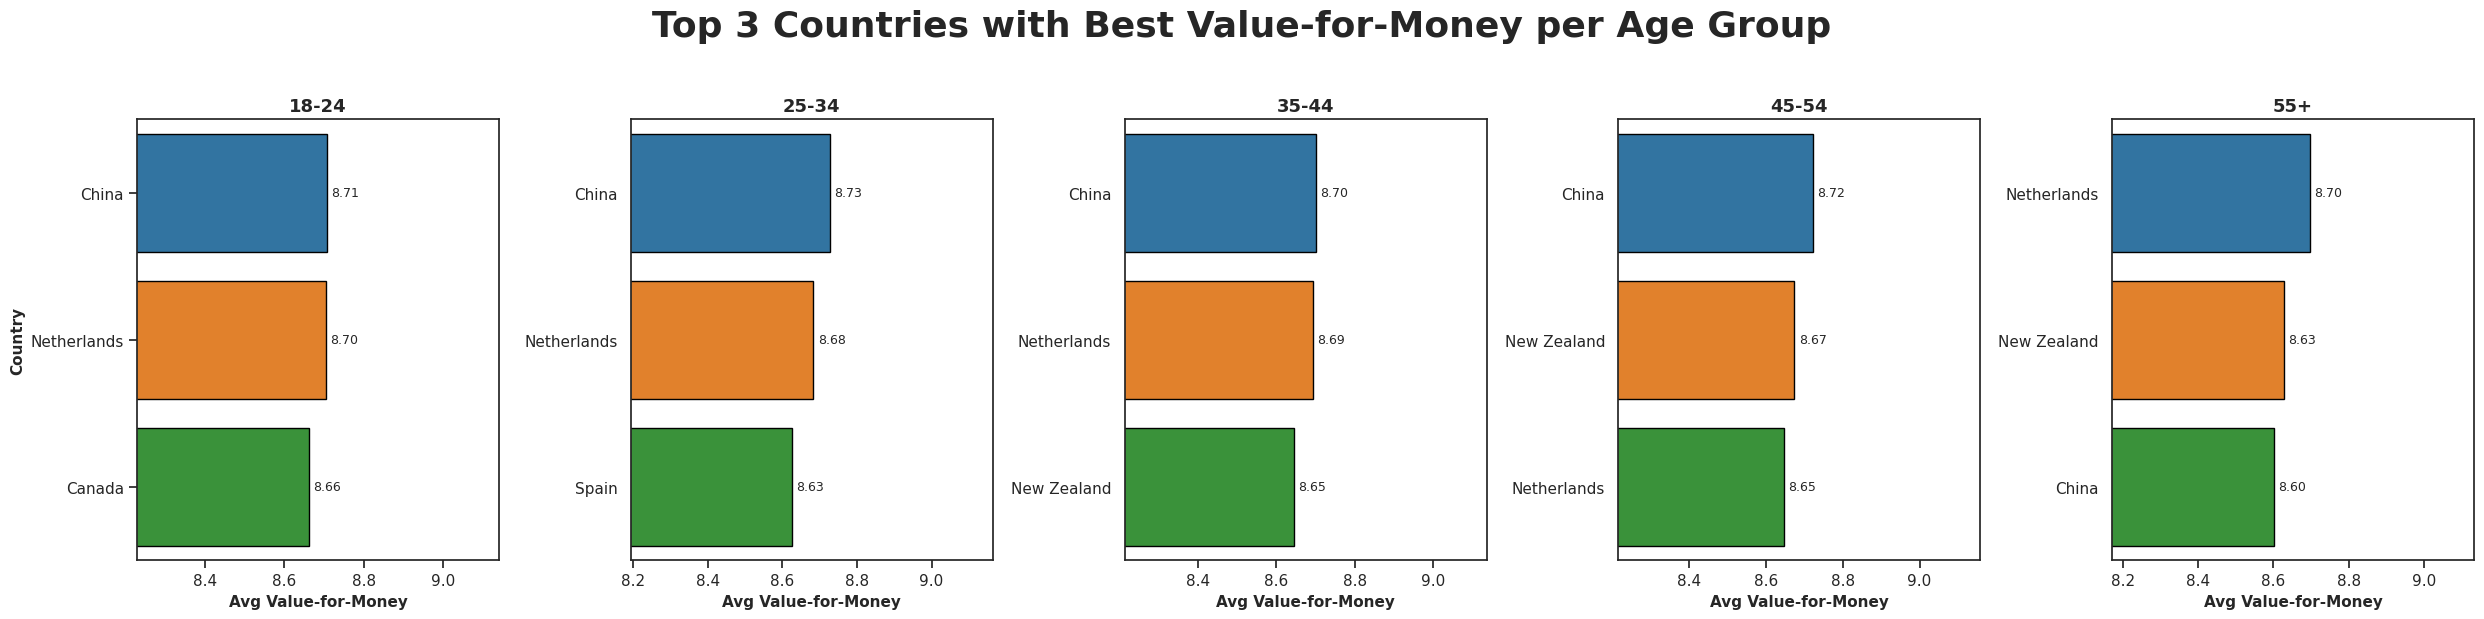

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set(style="ticks") 


age_groups = top3['user_age_group'].unique()

# create one plot for each age group
plt.figure(figsize=(5 * len(age_groups), 6))

for i, group in enumerate(age_groups, start=1):
    # filter only this age group
    group_data = top3[top3['user_age_group'] == group].sort_values(
        by='score_value_for_money', ascending=False
    )

    # a subplot
    plt.subplot(1, len(age_groups), i)


    sns.barplot(
        data=group_data,
        y='hotel_country',
        x='score_value_for_money',
        palette='tab10',  # bright colors
        edgecolor='black'
    )


    plt.title(f'{group}', fontsize=13, fontweight='bold')
    plt.xlabel('Avg Value-for-Money', fontsize=11, fontweight='bold')

    # only show y label on first plot
    if i == 1:
        plt.ylabel('Country', fontsize=11 , fontweight='bold')
    else:
        plt.ylabel('')
        plt.tick_params(axis='y', left=False)

    # add numbers on bars
    for container in plt.gca().containers:
        plt.bar_label(container, fmt='%.2f', fontsize=9, padding=3)

    # zoom in on the range to exaggerate differences
    min_score = group_data['score_value_for_money'].min()
    max_score = group_data['score_value_for_money'].max()
    plt.xlim(min_score * 0.95, max_score * 1.05)

plt.suptitle('Top 3 Countries with Best Value-for-Money per Age Group', 
             fontsize=26, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

Trying Features and models 

In [ ]:
#features 
import pandas as pd
import numpy as np

df = merged_df.copy()   

# Numeric safety: ensure review and base cols are numeric
num_cols = [
    'score_overall','score_cleanliness','score_comfort','score_facilities',
    'score_location','score_staff','score_value_for_money',
    'star_rating','cleanliness_base','comfort_base','facilities_base',
    'location_base','staff_base','value_for_money_base'
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# 1) per-dimension gap: review score minus hotel base
dims = {
    'cleanliness':'score_cleanliness',
    'comfort':'score_comfort',
    'facilities':'score_facilities',
    'location':'score_location',
    'staff':'score_staff',
    'value_for_money':'score_value_for_money'
}
for base_name, score_col in [('cleanliness_base','score_cleanliness'),
                             ('comfort_base','score_comfort'),
                             ('facilities_base','score_facilities'),
                             ('location_base','score_location'),
                             ('staff_base','score_staff'),
                             ('value_for_money_base','score_value_for_money')]:
    new_col = score_col + '_minus_' + base_name
    df[new_col] = df[score_col] - df[base_name]

# 2) overall gap: overall review vs mean of hotel base dimensions
base_mean_cols = ['cleanliness_base','comfort_base','facilities_base','location_base','staff_base','value_for_money_base']
df['hotel_base_mean'] = df[base_mean_cols].mean(axis=1)
df['overall_minus_hotel_base_mean'] = df['score_overall'] - df['hotel_base_mean']

# 3) relative value: value-for-money gap normalized by star_rating (avoid /0)
df['value_for_money_per_star'] = df['score_value_for_money'] / df['star_rating'].replace(0, np.nan)

# 4) simple aggregate review score (average of review dimensions)
review_dims = ['score_cleanliness','score_comfort','score_facilities','score_location','score_staff','score_value_for_money']
df['avg_review_dim'] = df[review_dims].mean(axis=1)

# 5) consistency measure: std of review dimensions (how consistent user scores are)
df['review_std'] = df[review_dims].std(axis=1)

# Quick fill / drop if necessary
df = df.fillna(0)   # or choose a different imputation strategy

# Inspect new features
df[[c for c in df.columns if '_minus_' in c] + ['overall_minus_hotel_base_mean','value_for_money_per_star','avg_review_dim','review_std']].head()
#score_X_minus_base_Y — shows how the customer's rating differs from the hotel’s baseline for that dimension. If guests systematically rate a hotel much lower than its base, that signals a gap between perceived and expected quality.
#overall_minus_hotel_base_mean — global “surprise” signal: does the overall experience exceed or fall short of the hotel’s typical standard? Useful to capture general sentiment vs expectation.
#value_for_money_per_star — normalises perceived value by hotel category. A 4-star hotel with poor value-for-money is different from a 2-star with the same score.
#avg_review_dim — compact summary of review dimensions (an alternative to score_overall).
#review_std — measures whether the review is consistent; high std → reviewer gave very different scores across dimensions (maybe noisy or picky).

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    # raw review scores
    'score_overall','score_cleanliness','score_comfort','score_facilities',
    'score_location','score_staff','score_value_for_money',
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    
    # hotel base
    'cleanliness_base','comfort_base','facilities_base',
    'location_base','staff_base','value_for_money_base',
    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    
    # derived quality features
    'score_cleanliness_minus_cleanliness_base','score_comfort_minus_comfort_base',
    'score_facilities_minus_facilities_base','score_location_minus_location_base',
    'score_staff_minus_staff_base','score_value_for_money_minus_value_for_money_base',
    'overall_minus_hotel_base_mean','value_for_money_per_star','avg_review_dim','review_std',
    # user features (numerical or encoded)
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    # raw review scores
    'score_overall','score_cleanliness','score_comfort','score_facilities',
    'score_location','score_staff','score_value_for_money',
    # hotel base
    'cleanliness_base','comfort_base','facilities_base',
    'location_base','staff_base','value_for_money_base',
    # derived quality features
    'score_cleanliness_minus_cleanliness_base','score_comfort_minus_comfort_base',
    'score_facilities_minus_facilities_base','score_location_minus_location_base',
    'score_staff_minus_staff_base','score_value_for_money_minus_value_for_money_base',
    'overall_minus_hotel_base_mean','value_for_money_per_star','avg_review_dim','review_std',
    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# target
df = df.copy()
df = df.dropna(subset=['country_group'])  
le_target = LabelEncoder()
y = le_target.fit_transform(df['country_group'])  # multi-class integers

# features: pick clean numeric + encode categorical
# numeric features (as from feature_list)
X_num = df[feature_list].copy()

# encode categorical user features
# traveller_type, user_gender, age_group -> one-hot
cat_cols = [c for c in ['traveller_type','user_gender','age_group'] if c in df.columns]
X_cat = pd.get_dummies(df[cat_cols], drop_first=True)

# final X
X = pd.concat([X_num.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)

# scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
import pandas as pd
import numpy as np

def remove_highly_correlated_features(df, threshold=0.85):
    """
    Remove features that are highly correlated with others (above threshold).
    Keeps the first feature in each correlated pair.
    Returns a reduced DataFrame and a list of dropped features.
    """
    corr_matrix = df.corr().abs()
    
    # Create an upper triangle mask (to avoid double-checking pairs)
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Find columns where any correlation is greater than threshold
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    
    print(f" Features to drop (correlation > {threshold}): {to_drop}")
    print(f" Remaining features: {len(df.columns) - len(to_drop)} of {len(df.columns)} kept.")
    
    return df.drop(columns=to_drop, errors='ignore'), to_drop

# Example use on your merged/engineered dataset
numeric_features = df.select_dtypes(include=[np.number])  # choose numeric only
clean_df, dropped = remove_highly_correlated_features(numeric_features, threshold=0.85)

# Your final feature matrix for modeling
X_final = clean_df.copy()
print("Final feature set shape:", X_final.shape)

In [ ]:
import seaborn as sns

#  the features you want to inspect for correlation
feature_list_Score_based = [
    'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities'
    , 'score_location', 'score_staff', 'score_value_for_money',
    'cleanliness_base', 'comfort_base', 'facilities_base', 'location_base', 
    'staff_base', 'value_for_money_base'

    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list_Score_based = [c for c in feature_list_Score_based if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list_Score_based].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns

#  the features you want to inspect for correlation
feature_list_Quality_based = [
    'overall_minus_hotel_base_mean', 'review_std'
    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list_Quality_based = [c for c in feature_list_Quality_based if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list_Quality_based].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# the features you want
feature_list_User_features = [
    'age_group', 'traveller_type', 'user_gender'
]

# keep only columns that exist
feature_list_User_features = [c for c in feature_list_User_features if c in df.columns]

# make a copy of those columns
corr_data = df[feature_list_User_features].copy()

# label encode each categorical column
encoder = LabelEncoder()
for col in corr_data.columns:
    corr_data[col] = encoder.fit_transform(corr_data[col].astype(str))

# compute correlation matrix
corr_df = corr_data.corr()

# plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Encoded User Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# combine X_final with encoded categorical features
cat_cols = [   # raw review scores
        'age_group', 'traveller_type', 'user_gender'
]
   
X_cat = pd.get_dummies(df[cat_cols], drop_first=True)

X_full = pd.concat([X_final.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)

# target
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df['country_group'])

print("Final features:", X_full.shape[1])
print("Target classes:", len(le.classes_))

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_full)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# Step 1: Import all needed libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Step 2: Train and evaluate
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Step 3: Show results
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective='multi:softmax', 
    num_class=len(le.classes_), 
    eval_metric='mlogloss', 
    random_state=42
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_))

In [ ]:
from tensorflow.keras import Sequential, Input, layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import SparseCategoricalAccuracy

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(len(le.classes_), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=[SparseCategoricalAccuracy(name='accuracy')]
)

early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop]
)

# evaluate
probs = model.predict(X_test)
y_pred_nn = probs.argmax(axis=1)

print("FFNN Accuracy:", accuracy_score(y_test, y_pred_nn))
print(classification_report(y_test, y_pred_nn, target_names=le.classes_))

the good one 

In [24]:
#new country group column
country_groups_map = {
    'United States': 'North_America', 'Canada': 'North_America',
    'Germany': 'Western_Europe', 'France': 'Western_Europe', 'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe', 'Spain': 'Western_Europe', 'Italy': 'Western_Europe',
    'Russia': 'Eastern_Europe',
    'China': 'East_Asia', 'Japan': 'East_Asia', 'South Korea': 'East_Asia',
    'Thailand': 'Southeast_Asia', 'Singapore': 'Southeast_Asia',
    'United Arab Emirates': 'Middle_East', 'Turkey': 'Middle_East',
    'Egypt': 'Africa', 'Nigeria': 'Africa', 'South Africa': 'Africa',
    'Australia': 'Oceania', 'New Zealand': 'Oceania',
    'Brazil': 'South_America', 'Argentina': 'South_America',
    'India': 'South_Asia',
    'Mexico': 'North_America_Mexico'
}

# 5.2 Apply the mapping to the 'user_country' column
merged_df['country_group'] = merged_df['user_country'].map(country_groups_map)

In [25]:
unmapped_count = merged_df['country_group'].isnull().sum()
print(f"Number of rows with unmapped 'user_country' : {unmapped_count}")

Number of rows with unmapped 'user_country' : 0


In [26]:
# Ensure IDs are treated as strings
merged_df['user_id'] = merged_df['user_id'].astype(str)
merged_df['hotel_id'] = merged_df['hotel_id'].astype(str)

# Check categorical columns
categorical_cols = ['user_gender', 'user_age_group', 'user_traveller_type',
                    'hotel_city', 'hotel_country', 'country_group']
for col in categorical_cols:
    merged_df[col] = merged_df[col].astype('category')

In [27]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   review_id                   50000 non-null  int64   
 1   user_id                     50000 non-null  object  
 2   hotel_id                    50000 non-null  object  
 3   score_overall               50000 non-null  float64 
 4   score_cleanliness           50000 non-null  float64 
 5   score_comfort               50000 non-null  float64 
 6   score_facilities            50000 non-null  float64 
 7   score_location              50000 non-null  float64 
 8   score_staff                 50000 non-null  float64 
 9   score_value_for_money       50000 non-null  float64 
 10  user_gender                 50000 non-null  category
 11  user_country                50000 non-null  object  
 12  user_age_group              50000 non-null  category
 13  user_traveller_t

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


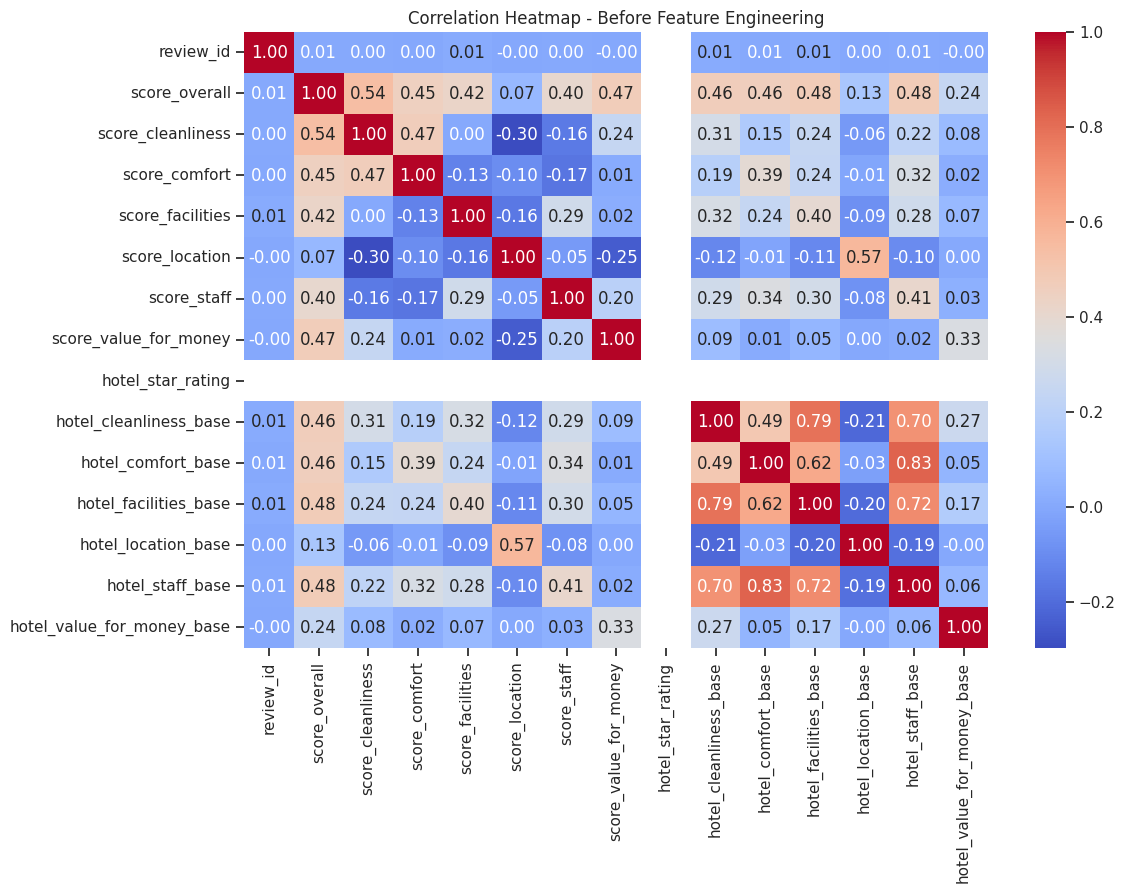

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numerical columns
num_df = merged_df.select_dtypes(include=['float64', 'int64'])

# Correlation matrix
corr_matrix = num_df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap - Before Feature Engineering")
plt.show()

In [29]:
#drop correlated columns
merged_df["hotel_quality_index"] = merged_df[
    ["hotel_staff_base", "hotel_comfort_base", "hotel_facilities_base",
     "hotel_cleanliness_base", "hotel_value_for_money_base"]
].mean(axis=1)

merged_df.drop(
    columns=[
        "hotel_staff_base", 
        "hotel_comfort_base", 
        "hotel_facilities_base",
        "hotel_cleanliness_base", 
        "hotel_value_for_money_base"
    ],
    inplace=True
)

merged_df.head()

,review_id,user_id,hotel_id,score_overall,score_cleanliness,score_comfort,score_facilities,score_location,score_staff,score_value_for_money,...,user_country,user_age_group,user_traveller_type,hotel_name,hotel_city,hotel_country,hotel_star_rating,hotel_location_base,country_group,hotel_quality_index
0,1,1600,1,8.7,8.6,8.7,8.5,9.0,8.8,8.7,...,New Zealand,25-34,Solo,The Azure Tower,New York,United States,5,9.5,Oceania,8.68
1,2,432,4,9.1,10.0,9.1,9.0,8.6,9.4,8.6,...,United Kingdom,35-44,Couple,Kyo-to Grand,Tokyo,Japan,5,8.5,Western_Europe,9.12
2,3,186,18,8.8,9.7,8.8,8.3,8.7,8.1,8.6,...,Spain,55+,Couple,Nile Grandeur,Cairo,Egypt,5,9.1,Western_Europe,8.64
3,4,1403,19,8.9,9.0,8.8,8.5,9.6,9.1,8.3,...,United Kingdom,35-44,Business,Gaudi's Retreat,Barcelona,Spain,5,9.7,Western_Europe,9.00
4,5,1723,17,9.1,8.9,9.5,9.3,8.3,9.4,8.9,...,Australia,45-54,Family,Kremlin Suites,Moscow,Russia,5,9.0,Oceania,9.02


In [30]:
#drop correlated columns
merged_df["review_quality_index"] = merged_df[
    [
        "score_cleanliness",
        "score_comfort",
        "score_facilities",
        "score_location",
        "score_staff",
        "score_value_for_money",
        "score_overall"
    ]
].mean(axis=1)

merged_df.drop(
    columns=[
        "score_cleanliness",
        "score_comfort",
        "score_facilities",
        "score_location",
        "score_staff",
        "score_value_for_money",
        "score_overall"
    ],
    inplace=True
)

merged_df.head()

,review_id,user_id,hotel_id,user_gender,user_country,user_age_group,user_traveller_type,hotel_name,hotel_city,hotel_country,hotel_star_rating,hotel_location_base,country_group,hotel_quality_index,review_quality_index
0,1,1600,1,Female,New Zealand,25-34,Solo,The Azure Tower,New York,United States,5,9.5,Oceania,8.68,8.714286
1,2,432,4,Female,United Kingdom,35-44,Couple,Kyo-to Grand,Tokyo,Japan,5,8.5,Western_Europe,9.12,9.114286
2,3,186,18,Female,Spain,55+,Couple,Nile Grandeur,Cairo,Egypt,5,9.1,Western_Europe,8.64,8.714286
3,4,1403,19,Female,United Kingdom,35-44,Business,Gaudi's Retreat,Barcelona,Spain,5,9.7,Western_Europe,9.00,8.885714
4,5,1723,17,Male,Australia,45-54,Family,Kremlin Suites,Moscow,Russia,5,9.0,Oceania,9.02,9.057143


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


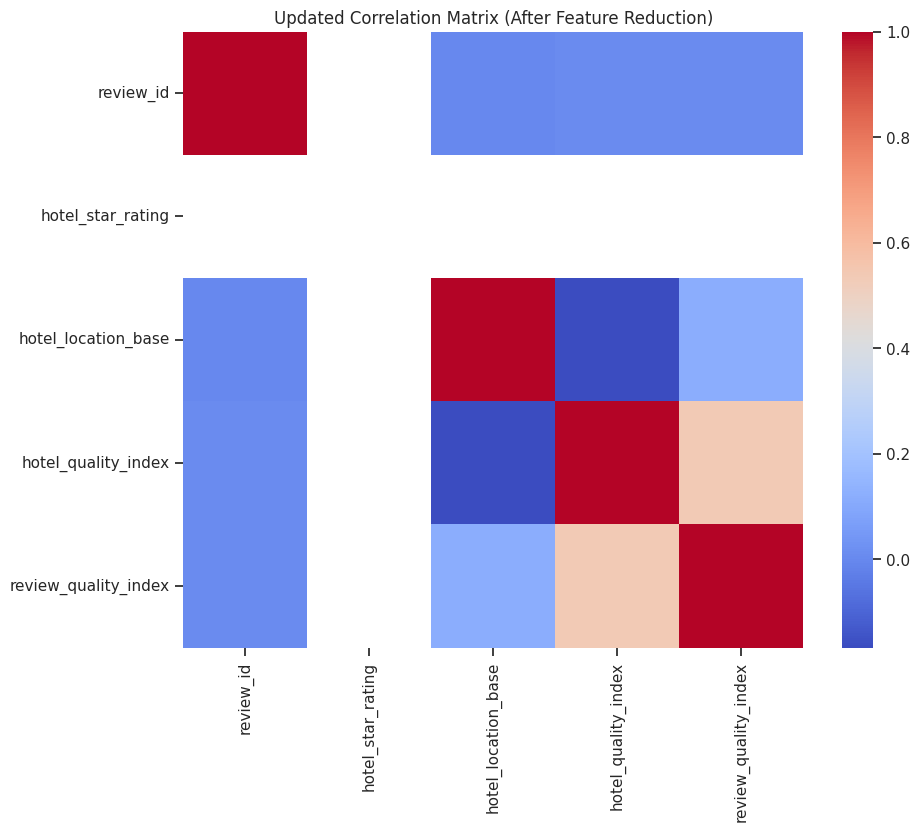

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(merged_df.corr(numeric_only=True), cmap="coolwarm", annot=False)
plt.title("Updated Correlation Matrix (After Feature Reduction)")
plt.show()

In [33]:
from sklearn.preprocessing import LabelEncoder

# Initialize encoder
le = LabelEncoder()

# Encode each categorical column
for col in categorical_cols:
    merged_df[col] = le.fit_transform(merged_df[col])

In [34]:
#scale 
from sklearn.preprocessing import StandardScaler

# Identify numeric columns
numeric_cols = ['hotel_star_rating', 'hotel_location_base', 'hotel_quality_index', 'review_quality_index']

# Initialize scaler
scaler = StandardScaler()

# Fit and transform
merged_df[numeric_cols] = scaler.fit_transform(merged_df[numeric_cols])

In [35]:
merged_df

,review_id,user_id,hotel_id,user_gender,user_country,user_age_group,user_traveller_type,hotel_name,hotel_city,hotel_country,hotel_star_rating,hotel_location_base,country_group,hotel_quality_index,review_quality_index
0,1,1600,1,0,New Zealand,1,3,The Azure Tower,14,24,0.0,0.660425,6,-1.279092,-1.020876
1,2,432,4,0,United Kingdom,2,1,Kyo-to Grand,22,10,0.0,-2.216066,10,1.062655,1.101985
2,3,186,18,0,Spain,4,1,Nile Grandeur,5,5,0.0,-0.490171,10,-1.491978,-1.020876
3,4,1403,19,0,United Kingdom,2,0,Gaudi's Retreat,2,19,0.0,1.235723,10,0.423997,-0.111079
4,5,1723,17,1,Australia,3,2,Kremlin Suites,12,15,0.0,-0.777820,6,0.530440,0.798719
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,1786,24,0,Mexico,3,0,The Savannah House,9,14,0.0,-1.065470,5,-1.917751,-3.143737
49996,49997,1739,8,0,New Zealand,2,1,Copacabana Lux,16,2,0.0,0.660425,6,-0.959763,-0.565978
49997,49998,1566,6,0,Russia,1,1,Marina Bay Zenith,20,16,0.0,1.235723,2,0.530440,0.798719
49998,49999,10,21,1,United Kingdom,3,3,The Bosphorus Inn,8,21,0.0,0.085127,10,-0.321105,0.419637


In [36]:
# new feature columns relations
user_review_count = merged_df.groupby('user_id')['review_id'].count().rename('user_review_count') # How many reviews this specific user has ever written.
merged_df = merged_df.merge(user_review_count, on='user_id')

hotel_avg_quality = merged_df.groupby('hotel_id')['hotel_quality_index'].mean().rename('hotel_avg_quality') # What is the average quality score that all users gave this specific hotel?
merged_df = merged_df.merge(hotel_avg_quality, on='hotel_id')

merged_df['user_type_location_interaction'] = merged_df['user_traveller_type'] * merged_df['hotel_location_base'] # How much does this type of traveler care about location?
 
merged_df['user_gender_quality_interaction'] = merged_df['user_gender'] * merged_df['hotel_quality_index'] # How does this gender group rate quality?

merged_df['user_type_review_interaction'] = merged_df['user_traveller_type'] * merged_df['review_quality_index'] # What is the mood of this traveler type?

merged_df['user_avg_review'] = merged_df.groupby('user_id')['review_quality_index'].transform('mean') # Average review per user

merged_df['user_review_count'] = merged_df.groupby('user_id')['review_quality_index'].transform('count') # Count of reviews per user

merged_df['user_unique_hotels'] = merged_df.groupby('user_id')['hotel_id'].transform('nunique') # Number of unique hotels per user

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


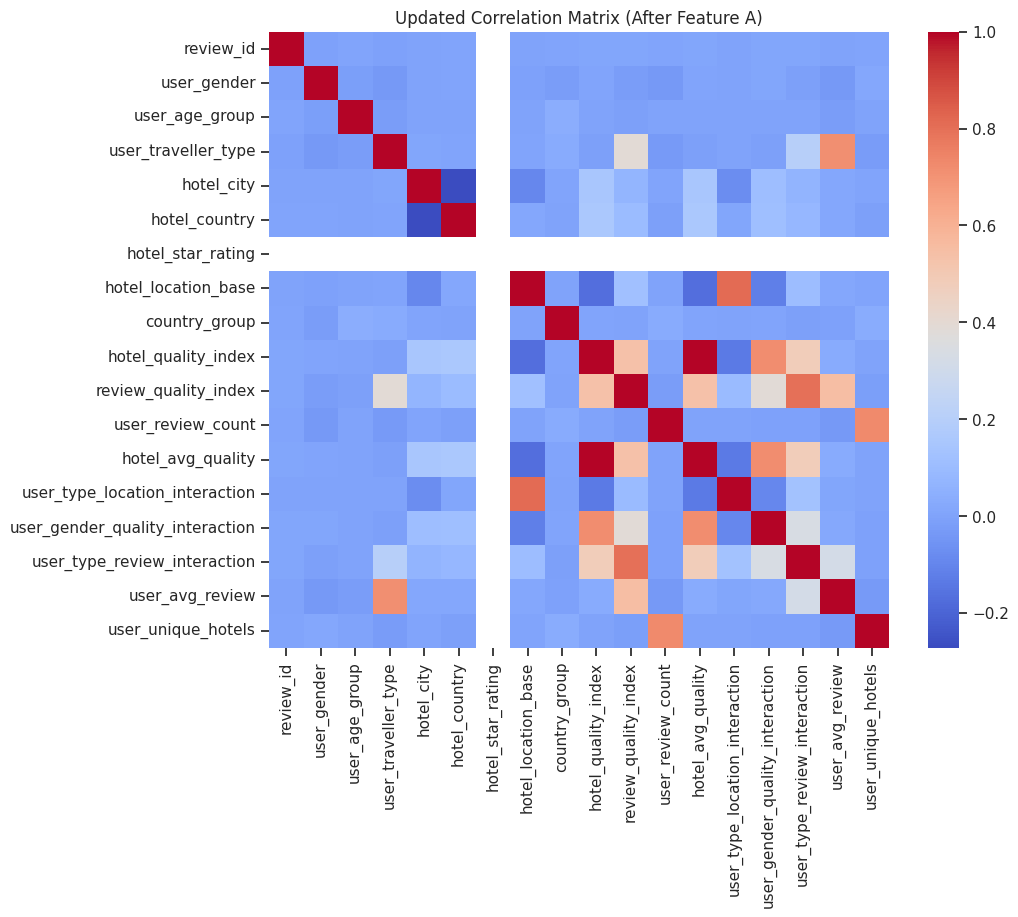

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(merged_df.corr(numeric_only=True), cmap="coolwarm", annot=False)
plt.title("Updated Correlation Matrix (After Feature A)")
plt.show()

In [38]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [39]:
# Define target
target_column = 'country_group'  # this is what we want to predict
y = merged_df[target_column]

# Define features
X = merged_df[[
    'user_gender', 'user_age_group', 'user_traveller_type',
    'hotel_star_rating', 'hotel_location_base',
    'hotel_quality_index', 'review_quality_index',
    'user_type_location_interaction',
    'user_gender_quality_interaction',
    'user_type_review_interaction',
    'user_avg_review', 'user_review_count', 'user_unique_hotels',
]]

print("Features (X) columns:", X.columns.tolist())
print("Target (y) column:", target_column)

Features (X) columns: ['user_gender', 'user_age_group', 'user_traveller_type', 'hotel_star_rating', 'hotel_location_base', 'hotel_quality_index', 'review_quality_index', 'user_type_location_interaction', 'user_gender_quality_interaction', 'user_type_review_interaction', 'user_avg_review', 'user_review_count', 'user_unique_hotels']
Target (y) column: country_group


In [40]:
#encode categories
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
le = LabelEncoder()
for col in categorical_cols:
    X[col] = le.fit_transform(X[col])